# ML_Team_Project

## [MNIST 데이터셋을 활용한 숫자, 전경색, 배경색 분류기 생성]

### 팀 명: MLS - Machine Learning Specialist
### 팀 장: 박현빈 - 20201589
### 팀 원: 고혜진 - 20221582
### 팀 원: 이건아 - 20201599
### 팀 원: 조민규 - 20201611

#### 1. 폰트를 사용한 MNIST 데이터셋 생성

생성된 이미지 데이터 크기: (120000, 28, 28)
생성된 레이블 데이터 크기: (120000,)


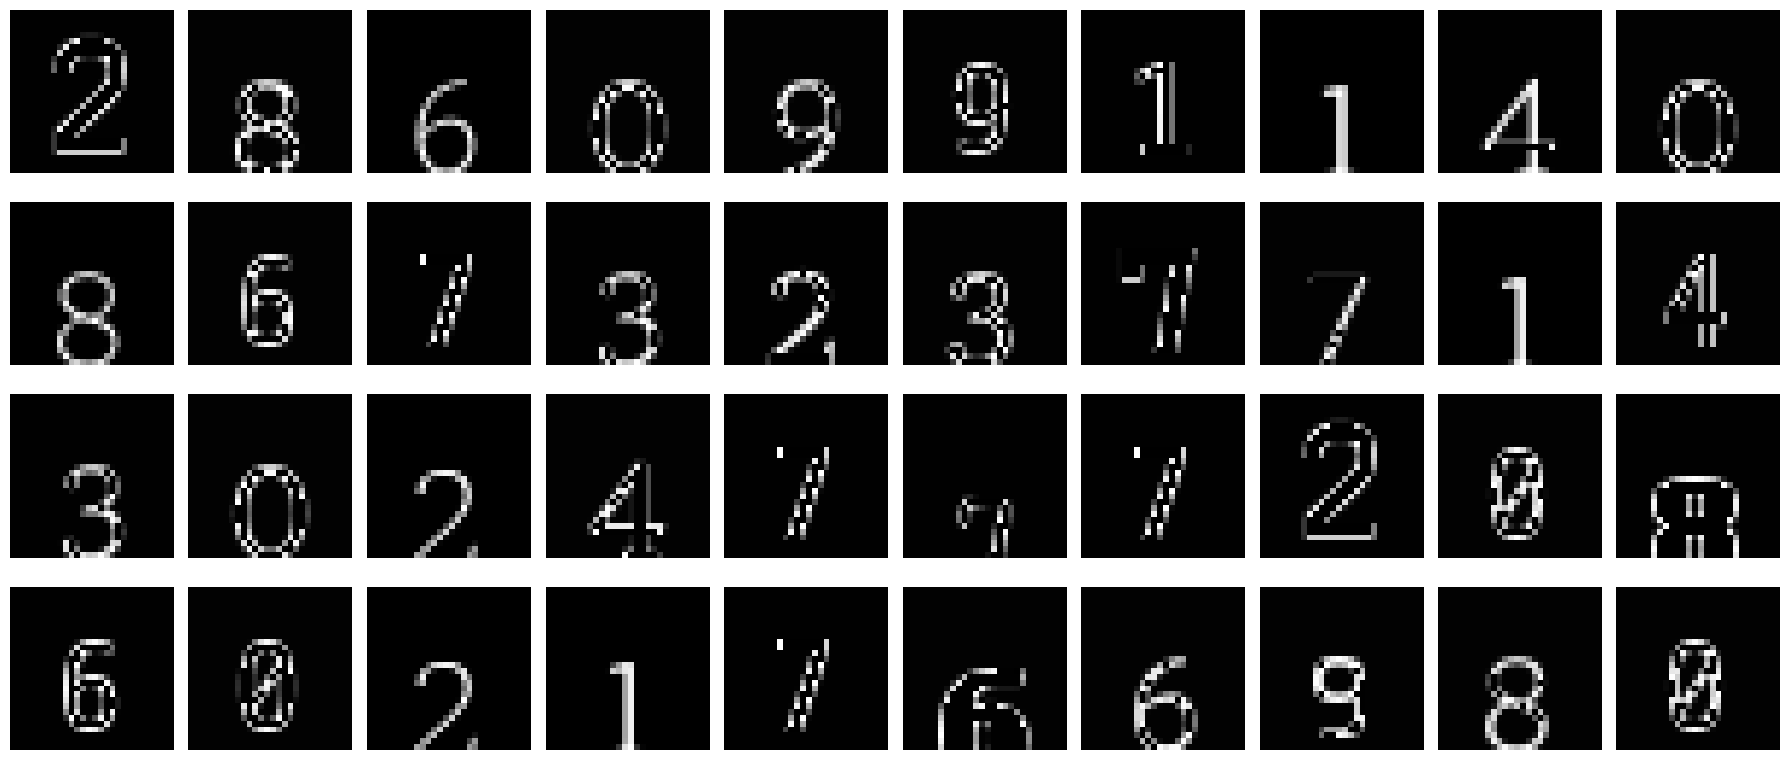

In [ ]:
from PIL import Image, ImageDraw, ImageFont
import numpy as np
import random
import os
import matplotlib.pyplot as plt
from glob import glob


# 폰트 경로 읽기
FONT_PATHS = glob('./fonts/**/*.ttf', recursive=True)

# MNIST와 동일한 이미지 크기와 폰트 크기 설정
IMAGE_SIZE = (28, 28)  # 이미지 크기 28X28
FONT_SIZE = 22         # 폰트 크기

def generate_digit_image(digit, font_path):
    """지정된 폰트로 특정 숫자 이미지를 생성하는 함수"""
    # 흰 배경의 이미지를 생성
    image = Image.new("L", IMAGE_SIZE, 255)
    draw = ImageDraw.Draw(image)

    # 폰트 로드
    try:
        font = ImageFont.truetype(font_path, FONT_SIZE)
    except IOError:
        print(f"폰트를 불러올 수 없습니다: {font_path}")
        return None

    # 텍스트 경계 계산
    bbox = draw.textbbox((0, 0), str(digit), font=font)
    text_width, text_height = bbox[2] - bbox[0], bbox[3] - bbox[1]

    # 숫자 가운데 정렬
    position = ((IMAGE_SIZE[0] - text_width) // 2, (IMAGE_SIZE[1] - text_height) // 2)
    draw.text(position, str(digit), fill=0, font=font)  # 검은색 숫자 (0은 검정)
    return np.array(image)

# 데이터셋 생성
NUM_SAMPLES = 120000
digits = list(range(10))
images = []
labels = []

for i in range(NUM_SAMPLES):
    # 숫자와 폰트를 랜덤하게 선택
    digit = random.choice(digits)
    font_path = random.choice(FONT_PATHS)

    # 이미지 생성
    image = generate_digit_image(digit, font_path)
    if image is not None:
        images.append(image)
        labels.append(digit)

# 생성된 데이터를 numpy 배열로 변환
images = np.array(images)
labels = np.array(labels)

print(f"생성된 이미지 데이터 크기: {images.shape}")
print(f"생성된 레이블 데이터 크기: {labels.shape}")

# 데이터셋 시각화
fig, axes = plt.subplots(4, 10, figsize=(18, 8))
for row in range(4):
    for col in range(10):

        # 0에서 9 사이의 숫자 랜덤하게 선택
        digit = np.random.randint(0, 10)

        # 폰트 경로 리스트에서 하나의 폰트 랜덤하게 선택
        font_path = random.choice(FONT_PATHS)

        # 선택된 폰트로 숫자 이미지 생성
        image = generate_digit_image(digit, font_path)

        axes[row, col].imshow(1 - image, cmap='gray')
        axes[row, col].axis('off')  # 축 비활설화
plt.tight_layout()
plt.show()


#### 2. 생성된 데이터셋에 전경색과 배경색 추가

10000/120000 색칠 완료
20000/120000 색칠 완료
30000/120000 색칠 완료
40000/120000 색칠 완료
50000/120000 색칠 완료
60000/120000 색칠 완료
70000/120000 색칠 완료
80000/120000 색칠 완료
90000/120000 색칠 완료
100000/120000 색칠 완료
110000/120000 색칠 완료
120000/120000 색칠 완료
2번: 전경색과 배경색 추가 완료!
색상 추가된 이미지 데이터 크기: (120000, 28, 28, 3)


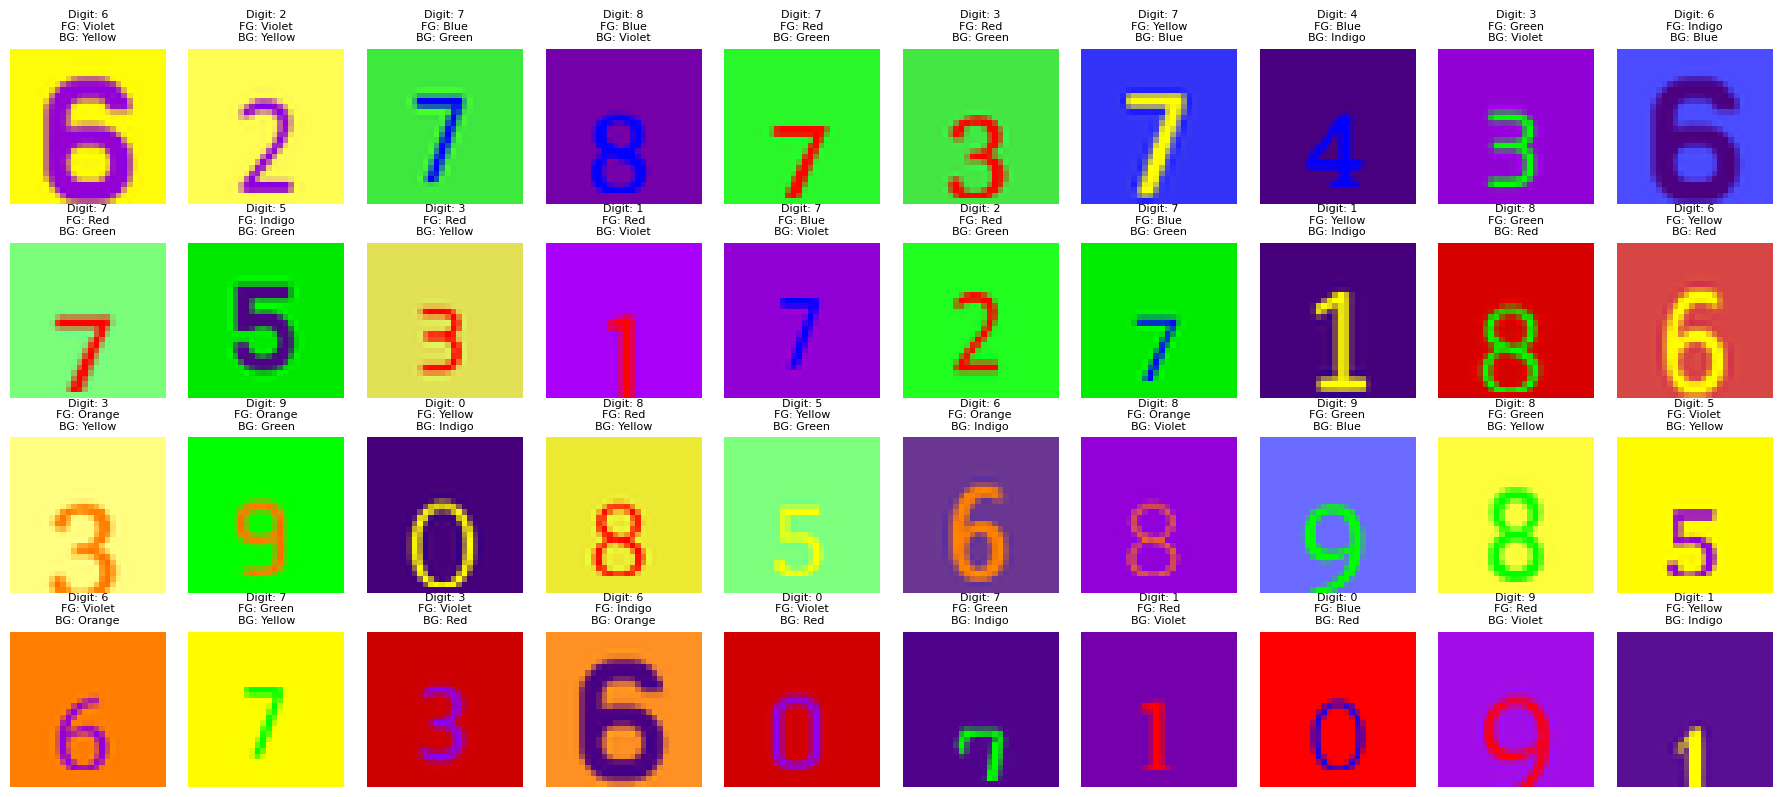

In [ ]:
from PIL import Image, ImageOps, ImageEnhance
import numpy as np
import random
import matplotlib.pyplot as plt

# 무지개 색상 RGB 값 정의
RAINBOW_COLORS = [
    (255, 0, 0),    # 빨강
    (255, 127, 0),  # 주황
    (255, 255, 0),  # 노랑
    (0, 255, 0),    # 초록
    (0, 0, 255),    # 파랑
    (75, 0, 130),   # 남색
    (148, 0, 211)   # 보라
]

# RGB 값을 각 색상 이름으로 맵핑
RGB_TO_COLOR_NAME = {
    (255, 0, 0): "Red",
    (255, 127, 0): "Orange",
    (255, 255, 0): "Yellow",
    (0, 255, 0): "Green",
    (0, 0, 255): "Blue",
    (75, 0, 130): "Indigo",
    (148, 0, 211): "Violet"
}

def rgb_to_color_name(rgb):
    """RGB 값을 색상 이름으로 변환"""
    return RGB_TO_COLOR_NAME.get(rgb, "Unknown")

def get_random_rainbow_color():
    """무작위로 전경색 또는 배경색을 선택합니다."""
    return random.choice(RAINBOW_COLORS)

def adjust_color_saturation_and_brightness(color, saturation_factor=1.0, brightness_factor=1.0):
    """
    단일 RGB 색상에 감도(채도)와 명도를 조절합니다.

    Parameters:
        color (tuple): 원본 RGB 색상
        saturation_factor (float): 채도 조정 비율 (기본 1.0)
        brightness_factor (float): 명도 조정 비율 (기본 1.0)

    Returns:
        tuple: 조정된 RGB 색상
    """
    # RGB 색상을 HSV로 변환
    hsv_color = Image.new("RGB", (1, 1), color).convert("HSV")
    h, s, v = hsv_color.getpixel((0, 0))

    # 채도와 명도 조정
    s = int(s * saturation_factor)
    v = int(v * brightness_factor)
    s = min(255, max(0, s))  # 유효 범위 클램핑
    v = min(255, max(0, v))  # 유효 범위 클램핑

    # HSV를 다시 RGB로 변환
    adjusted_color = Image.new("HSV", (1, 1), (h, s, v)).convert("RGB")
    return adjusted_color.getpixel((0, 0))

def augment_image(image, bg_color_adjusted):
    """
    주어진 이미지를 대칭 변환, 확대, 축소, 크롭 등의 증강 기법을 적용합니다.
    Parameters:
        image (PIL.Image.Image): 입력 이미지
    Returns:
        PIL.Image.Image: 증강된 이미지
    """
    # 대칭 변환 (좌우)
    # if random.random() > 0.5:
    #     image = ImageOps.mirror(image)

    # 확대 및 축소
    scale_factor = random.uniform(0.8, 1.2)  # 80% ~ 120% 크기 조정
    new_size = (int(image.width * scale_factor), int(image.height * scale_factor))
    image = image.resize(new_size, Image.Resampling.LANCZOS)  # 변경된 부분

    # 원본 크기로 크롭
    if scale_factor > 1:  # 확대 시 크롭
        left = (image.width - 28) // 2
        top = (image.height - 28) // 2
        image = image.crop((left, top, left + 28, top + 28))
    elif scale_factor < 1:  # 축소 시 패딩
        new_image = Image.new("RGB", (28, 28), bg_color_adjusted)
        left = (28 - image.width) // 2
        top = (28 - image.height) // 2
        new_image.paste(image, (left, top))
        image = new_image

    return image
def colorize_digit(image_array, fg_color, bg_color):
    """숫자 이미지에 전경색과 배경색을 적용합니다."""
    # 넘파이 배열을 PIL 이미지로 변환 (Grayscale)
    pil_image = Image.fromarray(image_array).convert("L")

    # 배경색에 감도, 명도 조정 추가
    bg_color_adjusted = adjust_color_saturation_and_brightness(
        bg_color,
        saturation_factor=random.uniform(0.5, 1.5),  # 감도를 ±50% 범위로 조정
        brightness_factor=random.uniform(0.8, 1.2)  # 명도를 ±20% 범위로 조정
    )

    # 전경색과 배경색 적용
    colorized_image = ImageOps.colorize(pil_image, black=fg_color, white=bg_color_adjusted).convert("RGB")

    # 증강 적용
    colorized_image = augment_image(colorized_image, bg_color_adjusted)
    return colorized_image

# 컬러 데이터셋 생성
colored_images = []  # 전경색, 배경색 적용된 컬러 이미지
colored_labels = []  # 각 컬러 이미지의 레이블 (숫자, 전경색, 배경색)

for i, (image, label) in enumerate(zip(images, labels)):
    # 전경색, 배경색 각각 랜덤하게 선택
    fg_color = get_random_rainbow_color()
    bg_color = get_random_rainbow_color()
    while bg_color == fg_color:  # 전경색과 배경색이 같으면 배경색을 재선택
        bg_color = get_random_rainbow_color()

    # 전경색과 배경색 적용하여 컬러링
    colored_image = colorize_digit(image, fg_color, bg_color)

    # 컬러 이미지와 레이블 저장
    colored_images.append(np.array(colored_image))  # 컬러 이미지를 넘파이 배열로 저장
    colored_labels.append((label, fg_color, bg_color))  # 레이블 정보 저장

    # 진행 상태 출력
    if (i + 1) % 10000 == 0:  # 10,000번째 이미지마다 출력
        print(f"{i + 1}/{len(images)} 색칠 완료")

print("2번: 전경색과 배경색 추가 완료!")

colored_images = np.array(colored_images)
print(f"색상 추가된 이미지 데이터 크기: {colored_images.shape}")

# 데이터셋 시각화
fig, axes = plt.subplots(4, 10, figsize=(18, 8))

# 40개 샘플 이미지 표시
for idx, ax in enumerate(axes.flatten()):
    sample_idx = random.randint(0, len(colored_images) - 1)
    ax.imshow(colored_images[sample_idx])

    digit, fg_color, bg_color = colored_labels[sample_idx]
    fg_color_name = rgb_to_color_name(fg_color)
    bg_color_name = rgb_to_color_name(bg_color)

    # 제목으로 숫자, 전경색 이름, 배경색 이름 표시
    ax.set_title(f"Digit: {digit}\nFG: {fg_color_name}\nBG: {bg_color_name}", fontsize=8)
    ax.axis('off')  # 축 비활성화

plt.tight_layout()
plt.show()


#### 3. 데이터셋 분할

훈련 데이터 크기: (84000, 28, 28, 3)
검증 데이터 크기: (18000, 28, 28, 3)
테스트 데이터 크기: (18000, 28, 28, 3)
최종 훈련 데이터 크기: (84000, 28, 28, 3)
최종 훈련 레이블 크기: (84000,)
검증 데이터셋: 회전 및 노이즈 추가 완료!
테스트 데이터셋: 회전 및 노이즈 추가 완료!


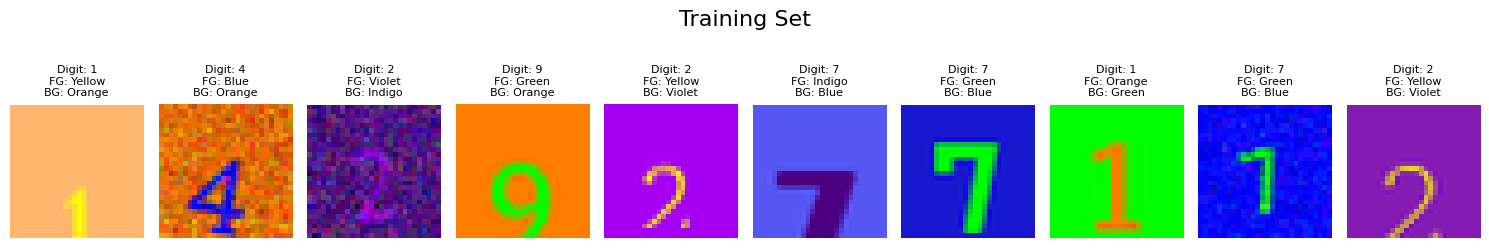

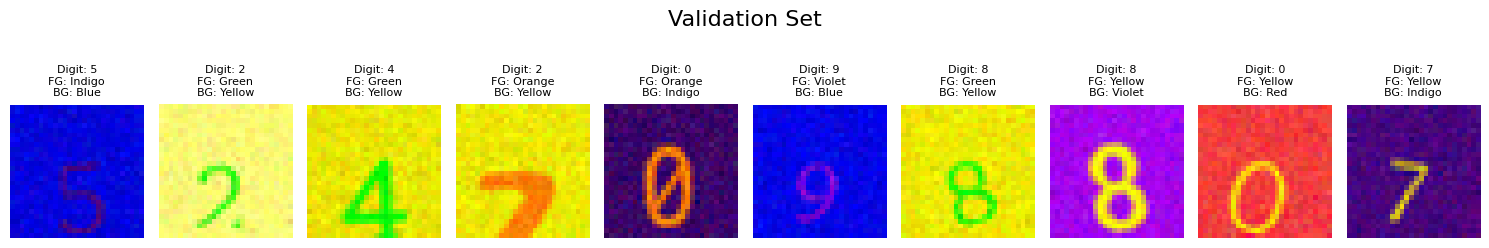

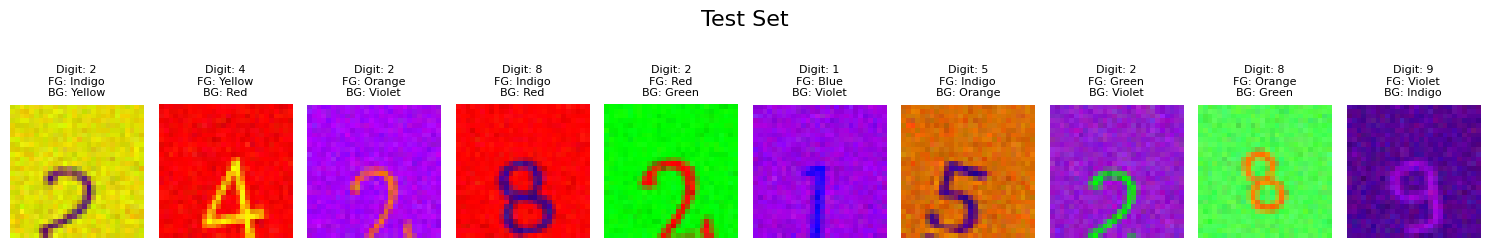

In [ ]:
import matplotlib.pyplot as plt
import random
from sklearn.model_selection import train_test_split
from scipy.ndimage import rotate
import numpy as np

digit_labels = np.array([label[0] for label in colored_labels])
foreground_labels = np.array([label[1] for label in colored_labels])
background_labels = np.array([label[2] for label in colored_labels])

X_train, X_temp, y_digit_train, y_digit_temp, y_fg_train, y_fg_temp, y_bg_train, y_bg_temp = train_test_split(
    colored_images, digit_labels, foreground_labels, background_labels, test_size=0.3, random_state=42
)

X_val, X_test, y_digit_val, y_digit_test, y_fg_val, y_fg_test, y_bg_val, y_bg_test = train_test_split(
    X_temp, y_digit_temp, y_fg_temp, y_bg_temp, test_size=0.5, random_state=42
)
print(f"훈련 데이터 크기: {X_train.shape}")
print(f"검증 데이터 크기: {X_val.shape}")
print(f"테스트 데이터 크기: {X_test.shape}")

def add_noise_to_images(images, noise_level=0.1):
    """
    이미지 데이터에 랜덤 노이즈를 추가합니다.
    Parameters:
        images (numpy.ndarray): 원본 이미지 데이터 (N, H, W, C)
        noise_level (float): 노이즈의 세기 (0~1 사이 값)
    Returns:
        numpy.ndarray: 노이즈가 추가된 이미지 데이터
    """
    noise = np.random.normal(loc=0.0, scale=noise_level, size=images.shape)
    noisy_images = images + noise * 255
    noisy_images = np.clip(noisy_images, 0, 255).astype(np.uint8)
    return noisy_images

def add_rotation_to_images(images, max_angle=20):
    """
    이미지 데이터에 랜덤 회전을 추가합니다.
    Parameters:
        images (numpy.ndarray): 원본 이미지 데이터 (N, H, W, C)
        max_angle (int): 최대 회전 각도
    Returns:
        numpy.ndarray: 회전이 추가된 이미지 데이터
    """
    rotated_images = []
    for image in images:
        angle = np.random.uniform(-max_angle, max_angle)  # 랜덤 회전 각도
        rotated = rotate(image, angle, reshape=False, mode='reflect')
        rotated_images.append(rotated)
    return np.array(rotated_images).astype(np.uint8)

import numpy as np

# 훈련 데이터에서 20%에만 증강 적용
augmentation_ratio = 0.2

# 훈련 데이터에서 증강을 적용할 샘플 수
num_augment = int(len(X_train) * augmentation_ratio)

# 훈련 데이터를 두 부분으로 분리
X_train_original = X_train[num_augment:]  # 증강 적용하지 않는 데이터
X_train_to_augment = X_train[:num_augment]  # 증강 적용 데이터

y_train_original = y_digit_train[num_augment:]  # 원본 데이터의 레이블
y_train_to_augment = y_digit_train[:num_augment]  # 증강 데이터의 레이블

# 노이즈 추가
X_train_augmented = add_noise_to_images(X_train_to_augment, noise_level=0.1)

# 회전율(최대 20%) 추가
X_train_augmented = add_rotation_to_images(X_train_augmented, max_angle=20)

# X_train_final 초기화 추가
X_train_final = np.concatenate([X_train_original, X_train_augmented], axis=0)

# 전경색과 배경색 레이블 결합
y_fg_train_final = np.concatenate([y_fg_train[num_augment:], y_fg_train[:num_augment]], axis=0)
y_bg_train_final = np.concatenate([y_bg_train[num_augment:], y_bg_train[:num_augment]], axis=0)

# 증강 데이터 뒤쪽에 몰리지 않도록 데이터 섞는 과정
shuffled_indices = np.random.permutation(len(X_train_final))
X_train_final = X_train_final[shuffled_indices]
y_train_final = np.concatenate([y_digit_train[num_augment:], y_digit_train[:num_augment]])[shuffled_indices]
y_fg_train_final = y_fg_train_final[shuffled_indices]
y_bg_train_final = y_bg_train_final[shuffled_indices]


# 결과 확인
print(f"최종 훈련 데이터 크기: {X_train_final.shape}")
print(f"최종 훈련 레이블 크기: {y_train_final.shape}")


# 검증 데이터셋에 회전 및 노이즈 추가
X_val_noisy_rotated = add_noise_to_images(X_val, noise_level=0.05)
X_val_noisy_rotated = add_rotation_to_images(X_val_noisy_rotated, max_angle=20)

# 테스트 데이터셋에 회전 및 노이즈 추가
X_test_noisy_rotated = add_noise_to_images(X_test, noise_level=0.05)
X_test_noisy_rotated = add_rotation_to_images(X_test_noisy_rotated, max_angle=20)

# 확인
print("검증 데이터셋: 회전 및 노이즈 추가 완료!")
print("테스트 데이터셋: 회전 및 노이즈 추가 완료!")


def visualize_dataset(images, digit_labels, fg_labels, bg_labels, title, num_samples=10):
    """
    데이터셋을 시각화하는 함수. 숫자, 전경색, 배경색 레이블을 함께 표시.

    Parameters:
        images (numpy.ndarray): 이미지 데이터셋 (N, H, W, C)
        digit_labels (numpy.ndarray): 숫자 레이블 데이터셋
        fg_labels (numpy.ndarray): 전경색 레이블 데이터셋
        bg_labels (numpy.ndarray): 배경색 레이블 데이터셋
        title (str): 그래프 제목
        num_samples (int): 표시할 샘플 이미지 개수
    """
    fig, axes = plt.subplots(1, num_samples, figsize=(15, 3))
    fig.suptitle(title, fontsize=16)

    for i in range(num_samples):
        idx = random.randint(0, len(images) - 1)
        ax = axes[i]
        ax.imshow(images[idx])
        ax.axis('off')

        digit = digit_labels[idx]
        fg_color_name = rgb_to_color_name(tuple(fg_labels[idx]))
        bg_color_name = rgb_to_color_name(tuple(bg_labels[idx]))
        ax.set_title(f"Digit: {digit}\nFG: {fg_color_name}\nBG: {bg_color_name}", fontsize=8)

    plt.tight_layout()
    plt.show()

# 훈련 데이터셋 시각화
visualize_dataset(X_train_final, y_train_final, y_fg_train_final, y_bg_train_final, title="Training Set", num_samples=10)

# 검증 데이터셋 시각화
visualize_dataset(X_val_noisy_rotated, y_digit_val, y_fg_val, y_bg_val, title="Validation Set", num_samples=10)

# 테스트 데이터셋 시각화
visualize_dataset(X_test_noisy_rotated, y_digit_test, y_fg_test, y_bg_test, title="Test Set", num_samples=10)




#### 4. 모델 훈련 및 평가

In [ ]:
import lightgbm as lgb
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder

# LightGBM은 2차원 배열 입력을 필요로 하므로, 데이터 2차원 배열 변환
X_train_flat = X_train_final.reshape(X_train_final.shape[0], -1)
X_val_flat = X_val_noisy_rotated.reshape(X_val_noisy_rotated.shape[0], -1)
X_test_flat = X_test_noisy_rotated.reshape(X_test_noisy_rotated.shape[0], -1)

# RGB 값을 고유 클래스 인덱스로 변환
def encode_rgb_labels(rgb_labels):
    """
    RGB 레이블을 고유 클래스 인덱스로 변환합니다.

    Parameters:
        rgb_labels (numpy.ndarray): RGB 값의 배열 (N, 3)

    Returns:
        numpy.ndarray: 고유 클래스 인덱스 레이블 (N,)
    """
    rgb_strings = [f"{r},{g},{b}" for r, g, b in rgb_labels]
    encoder = LabelEncoder()
    encoded_labels = encoder.fit_transform(rgb_strings)
    return encoded_labels, encoder

# 전경색과 배경색 레이블 변환
y_fg_train_encoded, fg_encoder = encode_rgb_labels(y_fg_train_final)
y_fg_val_encoded, _ = encode_rgb_labels(y_fg_val)
y_fg_test_encoded, _ = encode_rgb_labels(y_fg_test)

y_bg_train_encoded, bg_encoder = encode_rgb_labels(y_bg_train_final)
y_bg_val_encoded, _ = encode_rgb_labels(y_bg_val)
y_bg_test_encoded, _ = encode_rgb_labels(y_bg_test)

# LightGBM 모델 학습 및 평가
def train_and_evaluate_lgbm(X_train, y_train, X_val, y_val, X_test, y_test, label_name, encoder=None):
    print(f"[{label_name} 분류 모델 학습 시작]")

    # 모델 초기화
    model = lgb.LGBMClassifier(random_state=42)

    # 모델 학습
    model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        eval_metric="multi_logloss",
        callbacks=[lgb.log_evaluation(period=10), lgb.early_stopping(stopping_rounds=2)]
    )

    # 모델 평가
    print(f"\n[{label_name} 분류 결과]")
    preds = model.predict(X_test)
    print(f"테스트 정확도: {accuracy_score(y_test, preds):.4f}")
    print(classification_report(y_test, preds, target_names=encoder.classes_ if encoder else None))

    return model

# 숫자 분류
digit_model = train_and_evaluate_lgbm(
    X_train_flat, y_train_final, X_val_flat, y_digit_val, X_test_flat, y_digit_test, "숫자"
)

# 전경색 분류
foreground_model = train_and_evaluate_lgbm(
    X_train_flat, y_fg_train_encoded, X_val_flat, y_fg_val_encoded, X_test_flat, y_fg_test_encoded, "전경색", fg_encoder
)

# 배경색 분류
background_model = train_and_evaluate_lgbm(
    X_train_flat, y_bg_train_encoded, X_val_flat, y_bg_val_encoded, X_test_flat, y_bg_test_encoded, "배경색", bg_encoder
)

[숫자 분류 모델 학습 시작]
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.628894 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 541936
[LightGBM] [Info] Number of data points in the train set: 84000, number of used features: 2352
[LightGBM] [Info] Start training from score -2.294286
[LightGBM] [Info] Start training from score -2.296295
[LightGBM] [Info] Start training from score -2.309394
[LightGBM] [Info] Start training from score -2.291339
[LightGBM] [Info] Start training from score -2.298664
[LightGBM] [Info] Start training from score -2.294759
[LightGBM] [Info] Start training from score -2.304253
[LightGBM] [Info] Start training from score -2.305088
[LightGBM] [Info] Start training from score -2.318545
[LightGBM] [Info] Start training from score -2.313598
Training until validation scores don't improve for 2 rounds
[10]	valid_0's multi_logloss: 1.90957
[20]	valid_0's multi_logloss: 1.64247
[30]	valid_0's

In [ ]:
from sklearn.model_selection import cross_val_score

# 교차 검증 수행
bg_cross_val_scores = cross_val_score(
    foreground_model,  # 배경색 모델 사용
    X_train_flat,
    y_bg_train_encoded,
    cv=5,  # 5-fold 교차 검증
    scoring="accuracy"
)

print("교차 검증 정확도:", bg_cross_val_scores)
print("평균 정확도:", np.mean(bg_cross_val_scores))


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.529140 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 561376
[LightGBM] [Info] Number of data points in the train set: 67200, number of used features: 2352
[LightGBM] [Info] Start training from score -1.941960
[LightGBM] [Info] Start training from score -1.950086
[LightGBM] [Info] Start training from score -1.952599
[LightGBM] [Info] Start training from score -1.941752
[LightGBM] [Info] Start training from score -1.960178
[LightGBM] [Info] Start training from score -1.942582
[LightGBM] [Info] Start training from score -1.932459
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No furth

#### 5. 모델 성능 검증 및 최적화

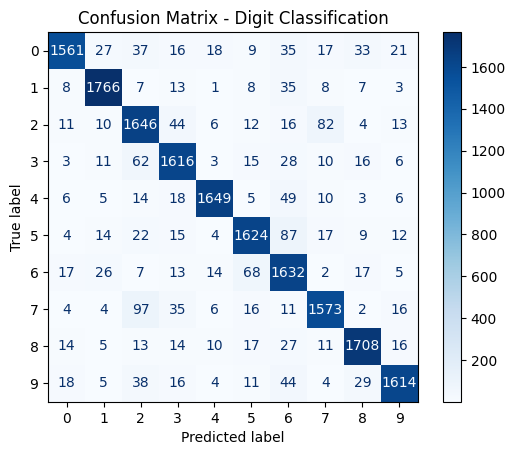

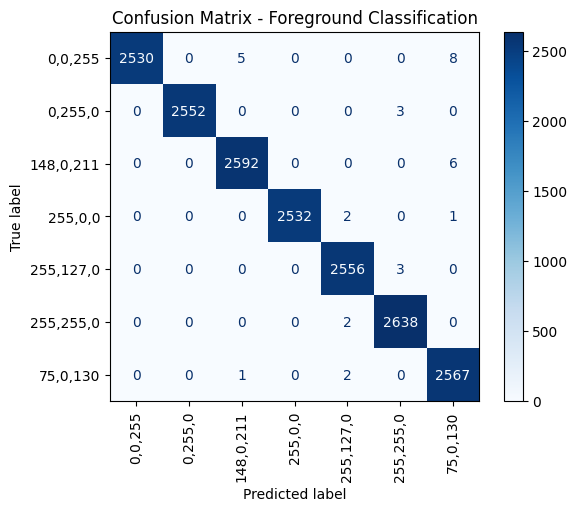

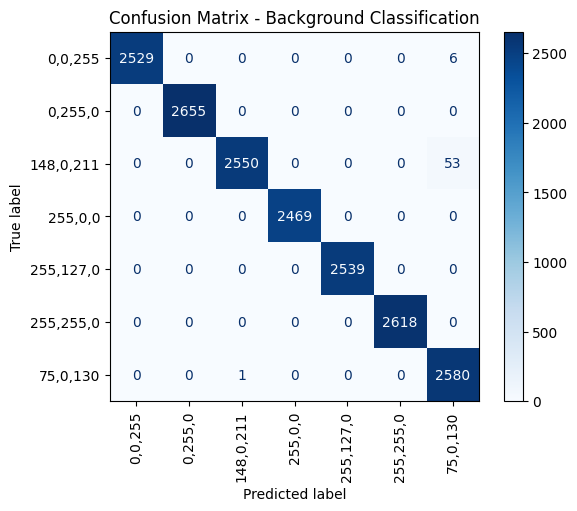

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 숫자 분류 Confusion Matrix
cm_digit = confusion_matrix(y_digit_test, digit_model.predict(X_test_flat))
ConfusionMatrixDisplay(cm_digit).plot(cmap='Blues', values_format='d')
plt.title("Confusion Matrix - Digit Classification")
plt.show()

# 전경색 분류 Confusion Matrix
fg_cm = confusion_matrix(y_fg_test_encoded, foreground_model.predict(X_test_flat))
fg_cm_display = ConfusionMatrixDisplay(confusion_matrix=fg_cm, display_labels=fg_encoder.classes_)
fg_cm_display.plot(cmap='Blues', xticks_rotation='vertical')
plt.title("Confusion Matrix - Foreground Classification")
plt.show()

# 배경색 분류 Confusion Matrix
bg_cm = confusion_matrix(y_bg_test_encoded, background_model.predict(X_test_flat))
bg_cm_display = ConfusionMatrixDisplay(confusion_matrix=bg_cm, display_labels=bg_encoder.classes_)
bg_cm_display.plot(cmap='Blues', xticks_rotation='vertical')
plt.title("Confusion Matrix - Background Classification")
plt.show()

